# 06 · Stage 6 — PSUT and PIOT

Stage 6 takes one reconciled optimiser run (the posterior flows `a*` of Stage 4, with the accounting structure behind them) and returns a tidy supply–use table (PSUT) from which supply, use and input–output views are cut on demand.

> **What this stage assumes**
>
> - **A11** — Stage 6 propagates point estimates only; the PIOT is a derived view of a PSUT and is never persisted (ADR 0037).
> - **A5** — σ is never dropped between stages; Stage 6 is the one documented exception, because a PSUT is a table of values (method.md §3.1.8).
> - **A10** — a satellite flow carries a value but sits outside its node's balance (ADR 0038); the PSUT keeps it in the table and in the `P` block.
> - Copper's choice: the input–output table is the market-share (industry-by-industry) construct, computed on demand from the reconciled PSUT (manuscript Table 2, ADR 0037).

In [1]:
from pathlib import Path
import json
import logging

import numpy as np
import pandas as pd
from IPython.display import Image, display

from pysuto.tutorial import toy
from pysuto.registry import PsutRunRegistry

RUNS = Path("runs")
pd.set_option("display.float_format", "{:.2f}".format)
logging.disable(logging.INFO)

Chapters 00–05 left a solved run tree in `runs/`. This chapter runs only Stage 6 on top of it.

The toy departs from copper in three plain ways here: it declares its own labels (`Gross` and `Content`, not copper's `Mass` and `CC`), it has no hard bands, and its world is closed, with no `ROW`. The stage itself does not care.

## The tidy table

The PSUT is **one table, one row per edge per period and valuation**. Everything else in this chapter is a view of it. `run_stage6` builds it from the latest solved run and writes it as a PSUT run.

In [2]:
run_id = toy.run_stage6(RUNS)
psut = PsutRunRegistry(str(RUNS / "proc" / "psut")).load(run_id)
print(psut)

2026-11-23 15:19:18,658 | pysuto.diag.psut | WARNING | sankey_tables 2005 Content: 6 link(s) ≤ 0 left out, -0.97003 kt Content in all


PSUT(acc='toy', valuations=['Gross', 'Content'], primary='Content', periods=2001..2005 (5), rows=420, blocks[Content]={'E': 15, 'O': 15, 'P': 45, 'S': 45, 'U': 60, 'Y': 30})


The primary valuation is the content one, so every number below is in `kt Content` unless it says `kt` (gross mass). Each row names its edge, its period, its valuation and the **block** it belongs to.

In [3]:
psut.table[psut.table["period"] == "2005"].head(6)

,period,valuation,block,edge_id,from_region,from_sector,from_entity,to_region,to_sector,to_entity,val
336,2005,Content,E,9,Montara,Deposit,SB,Montara,Mining,Process,10.58
337,2005,Content,E,19,Portua,Deposit,SB,Portua,Mining,Process,0.41
338,2005,Content,E,29,Isla,Deposit,SB,Isla,Mining,Process,3.33
339,2005,Content,O,339,Montara,Scrap,SB,Montara,Smelting,Process,0.57
340,2005,Content,O,349,Portua,Scrap,SB,Portua,Smelting,Process,2.90
341,2005,Content,O,359,Isla,Scrap,SB,Isla,Smelting,Process,0.91


Every edge of the accounting structure lands in exactly one block, or the build raises. The counts per block, for one period and one valuation:

In [4]:
rows = psut.table[(psut.table["period"] == "2005") & (psut.table["valuation"] == "Content")]
print(rows.groupby("block").size().to_string())

block
E     3
O     3
P     9
S     9
U    12
Y     6


## The six blocks of one region-year

A **block** is a matrix cut from that table. Reading the letters once is enough:

| block | from → to | meaning |
|---|---|---|
| `S` | process → commodity | supply: the useful output of a process |
| `U` | commodity → process | use: what a process takes in |
| `Y` | commodity → final demand | final use (`Use`, and the signed `Stock`) |
| `E` | nature → process | extraction from the deposit |
| `O` | secondary source → process | scrap fed back in |
| `P` | process → secondary sink | residual output (`Slag`, `Tailings`, `WasteRock`) |

A seventh block, `W` (discard to nature), exists in the framework and is empty in the toy. Here are Montara's six in 2005, zero rows and columns dropped. The first is supply: each of Montara's three processes makes one commodity.

In [5]:
def montara(name):
    m = psut.block(name, "2005")
    m = m.loc["Montara"] if "process" in m.index.names else m.loc[:, "Montara"]
    return m.loc[(m != 0).any(axis=1), (m != 0).any(axis=0)]

montara("S")

region       Montara            
flow     Concentrate Metal   Ore
process                         
Milling         9.50  0.00  0.00
Mining          0.00  0.00 10.58
Smelting        0.00  2.52  0.00

Use. Montara's Milling takes ore from Montara; its Smelting takes concentrate from Montara, Isla and Portua alike (the columns are the users, the rows the commodity and the region it came from).

In [6]:
montara("U")

process              Milling  Smelting
region  flow                          
Isla    Concentrate     0.00     -0.01
Montara Concentrate     0.00      2.03
        Ore            10.58      0.00
Portua  Concentrate     0.00      0.01

Final use is the end of the chain. `Stock` is signed: a negative value is metal drawn from stock.

In [7]:
montara("Y")

,final_demand,Stock,Use
region,flow,,
Montara,Metal,-0.23,2.74


The three boundary blocks: extraction `E`, secondary input `O`, residual output `P`.

In [8]:
for name in ("E", "O", "P"):
    display(montara(name))

,process,Mining
region,nature,
Montara,Deposit,10.58


,process,Smelting
region,secondary,
Montara,Scrap,0.57


region    Montara         
secondary    Slag Tailings
process                   
Milling      0.00     1.08
Smelting     0.08     0.00

Every process is a node with inputs and outputs: `U + E + O` in, `S + P + W` out. The closing test of a PSUT is that they agree. In `Content` they do, to rounding, for all nine processes:

In [9]:
def balance(valuation):
    S, U, E, O, P, W = (psut.block(b, "2005", valuation) for b in "SUEOPW")
    inflow, outflow = U.sum(axis=0) + E.sum(axis=0) + O.sum(axis=0), S.sum(axis=1) + P.sum(axis=1) + W.sum(axis=1)
    return pd.DataFrame({"in": inflow, "out": outflow, "out − in": outflow - inflow})

balance("Content").round(4)

in   out  out − in
region  process                       
Isla    Milling   3.33  3.33     -0.00
        Mining    3.33  3.33      0.00
        Smelting  4.38  4.38      0.00
Montara Milling  10.58 10.58     -0.00
        Mining   10.58 10.58      0.00
        Smelting  2.60  2.60      0.00
Portua  Milling   0.41  0.41      0.00
        Mining    0.41  0.41     -0.00
        Smelting 10.26 10.26     -0.00

In `Gross` they do not, for Mining. That is the satellite of ADR 0038 (assumption A10): waste rock leaves Mining as a flow in `kt` but sits outside Mining's balance, so the gap on each Mining row is exactly its `WasteRock` output.

In [10]:
balance("Gross").round(2).xs("Mining", level="process")

,in,out,out − in
region,,,
Isla,406.12,1218.36,812.24
Montara,1048.82,3146.47,2097.65
Portua,1.45,4.34,2.90


<details><summary>Going deeper: why the satellite is in the table at all</summary>

The solver's mass balance leaves waste rock out of Mining's node (ADR 0038), and the toy sets it to twice the ore, as copper's satellite does. Stage 6 does not re-derive balances; it classifies edges. A satellite edge is an ordinary `Process → SB` edge, so it falls in `P`, and the `Gross` table shows it. In `Content` the waste rock carries no orium, so the same edge is zero and the node balances.

The consequence for any input–output work: the `P` block is residual output, and a process-network calculus (below) treats it as leaving the system, not as an input to another process. A satellite therefore never inflates a multiplier.
</details>

## `aggregate()`: one world

`aggregate()` relabels regions and sectors by a concordance map, sums every row that now shares a key, and returns a new PSUT. Periods, valuations and blocks never merge. One string collapses every region to one label. With `keep_crossings=True` a row remembers whether its edge crossed a border *before* the collapse, so the traded share survives.

In [11]:
world = psut.aggregate(region="World", keep_crossings=True)
print(world)

PSUT(acc='toy', valuations=['Gross', 'Content'], primary='Content', periods=2001..2005 (5), rows=130, blocks[Content]={'E': 5, 'O': 5, 'P': 15, 'S': 15, 'U': 15, 'Y': 10}, aggregation=1 step(s))


Aggregation is a pushforward: it moves mass, it does not create or lose any. The table sum per valuation is unchanged, and the world's supply block is three numbers.

In [12]:
print(psut.table.groupby("valuation")["val"].sum().round(4).equals(world.table.groupby("valuation")["val"].sum().round(4)))
world.S("2005")

True


region                World            
flow            Concentrate Metal   Ore
region process                         
World  Milling        12.87  0.00  0.00
       Mining          0.00  0.00 14.32
       Smelting        0.00 16.70  0.00

The realized traded share of concentrate use in 2005, `kt Content` that crossed a border over all concentrate that smelters took in:

In [13]:
use = world.table[(world.table["block"] == "U") & (world.table["period"] == "2005") & (world.table["valuation"] == "Content")]
by_crossing = use.groupby("region_crossed")["val"].sum()
print(by_crossing.round(2).to_string())
print(f"traded share of concentrate use, 2005: {by_crossing[True] / by_crossing.sum():.2f} of the world total, in kt Content")

region_crossed
False   19.31
True     7.89
traded share of concentrate use, 2005: 0.29 of the world total, in kt Content


## The Sankey

A Sankey draws one period and one valuation of the table: the blocks as columns, edges as bands. The first figure is Plotly, interactive in VS Code or Jupyter; the second is the PNG that Stage 6 wrote beside the run through kaleido, which is what GitHub shows. Boundary inputs are green, supply and use blue, traded legs red, final use purple, residuals grey. A link at or below zero cannot be drawn: the build logs a warning with their total, and the toy's few small negative flows (no hard bands) are among them.

In [14]:
fig = psut.sankey("2005", unit="kt Content")
fig

2026-11-23 15:19:20,560 | pysuto.diag.psut | WARNING | sankey_tables 2005 Content: 6 link(s) ≤ 0 left out, -0.97003 kt Content in all


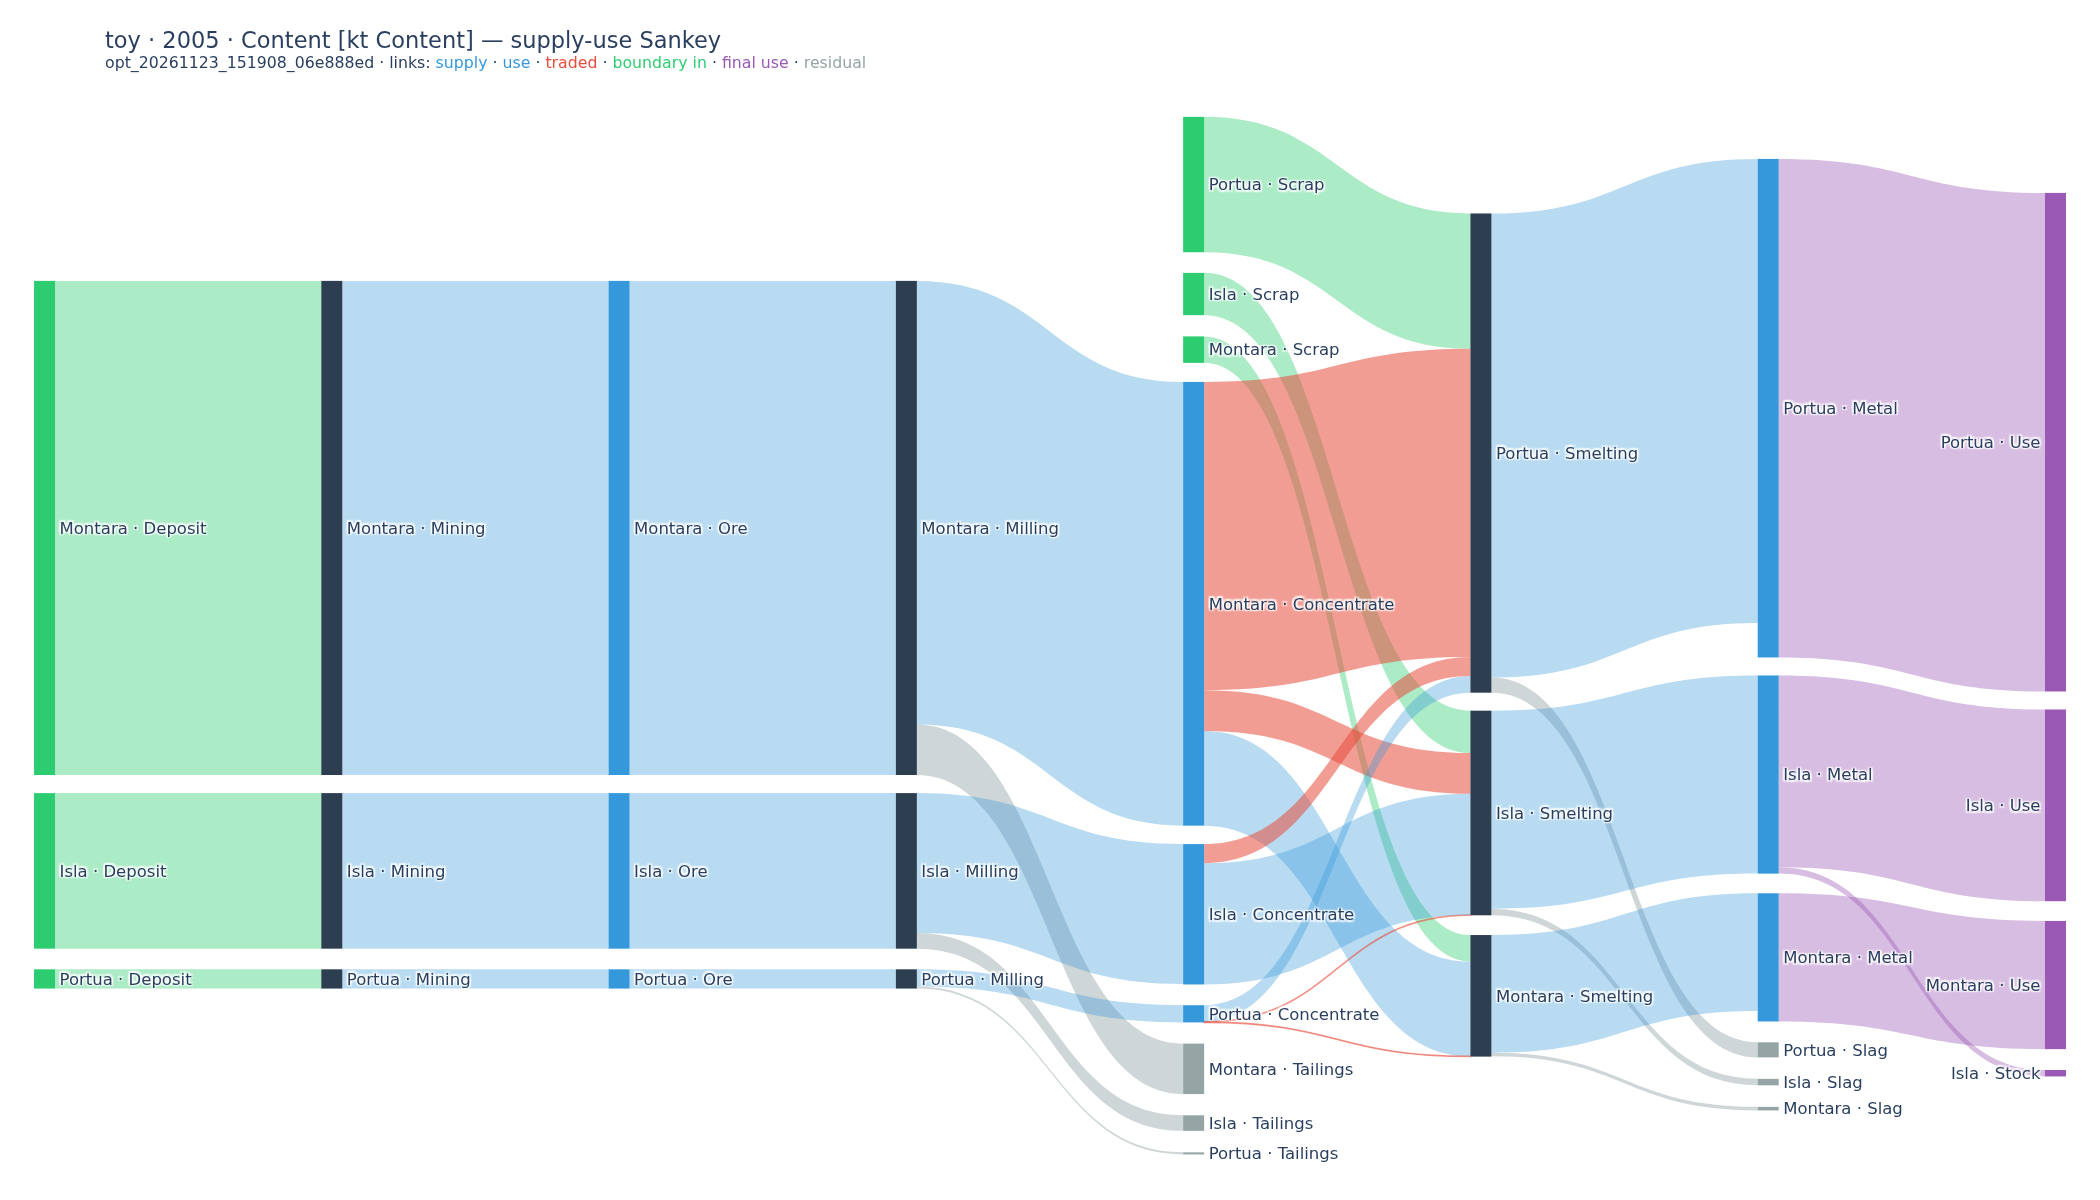

In [15]:
png = next((RUNS / "proc" / "psut" / run_id).glob("sankey_supply_use_*.png"))
Image(filename=str(png))

Read it left to right: Montara's deposit feeds its mine, its mill and an export leg to Portua's smelter (red), which also eats scrap and sends metal to `Use`. Isla stands apart; Portua mines almost nothing.

## From supply–use to input–output: `to_piot`

A PIOT is a *derived view*. `to_piot("market_share", level="L")` computes it from the PSUT on demand: market shares `D`, the process-by-process transactions `Z`, the technical coefficients `A = Z·x̂⁻¹` and the total requirements `L = (I − A)⁻¹`. It is never saved: ADR 0037 keeps one persisted table class, the PSUT.

On all nine regional processes `Z` is large. Dropping its empty rows and columns leaves the trade structure plain: row = supplying process, column = using process, `kt Content`, 2005.

In [16]:
piot = psut.to_piot("market_share", level="L")
Z = piot.Z("2005")
Z.loc[Z.any(axis=1), Z.any(axis=0)]

region             Isla          Montara           Portua         
process         Milling Smelting Milling Smelting Milling Smelting
region  process                                                   
Isla    Milling    0.00     2.60    0.00    -0.01    0.00     0.41
        Mining     3.33     0.00    0.00     0.00    0.00     0.00
Montara Milling    0.00     0.87    0.00     2.03    0.00     6.60
        Mining     0.00     0.00   10.58     0.00    0.00     0.00
Portua  Milling    0.00     0.01    0.00     0.01    0.00     0.36
        Mining     0.00     0.00    0.00     0.00    0.41     0.00

Montara's Milling supplies Portua's Smelting directly: that is the traded concentrate leg. Small negative entries are not a bug: the toy has no hard bands, so a posterior flow may dip below zero (the toy module's docstring says so).

To read all four matrices at once, aggregate to the world first. Three processes, one region.

In [17]:
wp = world.to_piot("market_share", level="L")
for name in ("D", "Z", "A", "L"):
    print(name); display(getattr(wp, name)("2005"))

D


region                World           
flow            Concentrate Metal  Ore
region process                        
World  Milling         1.00  0.00 0.00
       Mining          0.00  0.00 1.00
       Smelting        0.00  1.00 0.00

Z


region            World                
process         Milling Mining Smelting
region process                         
World  Milling     0.00   0.00    12.87
       Mining     14.32   0.00     0.00
       Smelting    0.00   0.00     0.00

A


region            World                
process         Milling Mining Smelting
region process                         
World  Milling     0.00   0.00     0.77
       Mining      1.11   0.00     0.00
       Smelting    0.00   0.00     0.00

L


region            World                
process         Milling Mining Smelting
region process                         
World  Milling     1.00  -0.00     0.77
       Mining      1.11   1.00     0.86
       Smelting    0.00   0.00     1.00

`D` is the identity: every commodity has one maker. (With a co-product such as the toy's `Dust` variant it would not be.) `A` is the input each process needs per unit of its own output: Milling takes about 1.1 `kt Content` of ore per `kt Content` of concentrate, Smelting about 0.8 of concentrate per `kt Content` of metal, the rest coming in as scrap.

`L` answers a question `A` cannot: how much of *every* process is needed, directly and indirectly, to deliver one unit of final demand. Its column sums are the **output multipliers**.

In [18]:
multipliers = wp.multipliers("2005")
print(multipliers.round(3).to_string())

region  process 
World   Milling    2.11
        Mining     1.00
        Smelting   2.63


Read the Smelting multiplier: to put one more `kt Content` of metal into final use, the world must produce that much metal plus the concentrate it needs, plus the ore that concentrate needs. The sum of those three outputs is the Smelting multiplier, `kt Content` of total output per `kt Content` of final demand. Mining's multiplier is exactly 1: nothing sits upstream of it. The same table also reproduces the system: `L·y = x`.

In [19]:
print(np.allclose(wp.L("2005").to_numpy() @ wp.y("2005").to_numpy(), wp.x("2005").to_numpy()))

True


<details><summary>Going deeper: x, y and what L cannot embody</summary>

`x = Z·1 + y` is each process's total output: what it hands to other processes plus what it hands to final use (here `Y` and the residual outputs `P`). `A` divides each column of `Z` by `x`, and `L·y = x` follows by construction, as the cell above verified.

Two edges of the calculus are worth knowing. A process with no useful output has a zero `A` column and cannot be in a cycle; a closed cycle with no leakage to final demand makes `I − A` singular, and `L` raises rather than returning a number. Neither happens in the toy. And since Stage 6 carries point estimates (A11), none of these matrices has an uncertainty band: for that, run Stage 5 and rebuild the PSUT from the posterior draws, which is a task for the reader, not for the pipeline.
</details>

## Exercise

**Exercise 6.1** — Verify that Σ supply = Σ use for one node. Take the commodity `Metal` of Portua in 2005: supply is what `Smelting` puts into it (block `S`), use is what leaves it (block `U` into processes, block `Y` into final demand, `Stock` included). Cover the next cell and try it first; `toy.solution("6.1")` prints the reference.

In [20]:
S, U, Y = psut.S("2005"), psut.U("2005"), psut.Y("2005")
supply = S.loc[:, ("Portua", "Metal")].sum()
use = U.loc[("Portua", "Metal")].sum() + Y.loc[("Portua", "Metal")].sum()
print(toy.check_6_1(RUNS, supply, use))

✓ 6.1  Metal[Portua] 2005: supply 9.9390 = use 9.9390 kt Content


## Where this run came from

Every run writes a sidecar. This one names the accounting structure it read (`parents.inputs`) and the opt run it was built from (`parents.upstream`):

In [21]:
meta = json.loads((RUNS / "proc" / "psut" / run_id / "metadata.json").read_text())
print(json.dumps(meta["parents"], indent=2))

{
  "inputs": {
    "acc": {
      "id": "toy",
      "version": 1,
      "date": "2026-11-23T15:18:48Z",
      "code": "195cd770",
      "label": "toy"
    }
  },
  "upstream": {
    "opt_run_id": "opt_20261123_151908_06e888ed",
    "const_run_id": "const_20261123_151905_b9419350"
  }
}


The six stages are done. Chapter 07 lifts the seal: the toy's ground truth and the one planted error.